# Credit Card Customer Segmentation
### Unsupervised Learning | K-Means, Agglomerative Clustering and DBSCAN

**Project goal:** Group credit-card customers by their usage behaviour so a bank can plan more relevant services, rewards and customer-support actions.

This notebook follows the practical-exam brief. It uses the public [Credit Card Dataset for Clustering](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata).

> **Before running:** Download `CC_GENERAL.csv` from Kaggle and place it inside the project's `data` folder. The notebook does not contain the dataset.

## 1. Import libraries

We use pandas and NumPy for data handling, Matplotlib and Seaborn for charts, and scikit-learn for preprocessing and clustering.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import linkage, dendrogram
import joblib

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load and inspect the dataset

If the file is not found, check its name and location. It should be `data/CC_GENERAL.csv`.

In [5]:
import os

print("Files inside data folder:")

for file in os.listdir("../data"):
    print(repr(file))

Files inside data folder:
'CC GENERAL.csv'
'README.md'


In [6]:
import pandas as pd

DATA_PATH = "../data/CC GENERAL.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.000000,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,C10007,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.000000,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,C10008,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.000000,0,12,2300.0,679.065082,532.033990,0.000000,12
8,C10009,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.000000,0,5,7000.0,688.278568,311.963409,0.000000,12
9,C10010,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.000000,0,3,11000.0,1164.770591,100.302262,0.000000,12


In [7]:
# Keep a copy of the customer identifier for reference, then remove it from modelling.
if "CUST_ID" in df.columns:
    customer_ids = df["CUST_ID"].copy()
    df = df.drop(columns=["CUST_ID"])
else:
    customer_ids = pd.Series(range(len(df)), name="CUST_ID")

print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


MINIMUM_PAYMENTS                    313
CREDIT_LIMIT                          1
BALANCE                               0
CASH_ADVANCE_FREQUENCY                0
PRC_FULL_PAYMENT                      0
PAYMENTS                              0
PURCHASES_TRX                         0
CASH_ADVANCE_TRX                      0
PURCHASES_INSTALLMENTS_FREQUENCY      0
BALANCE_FREQUENCY                     0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_FREQUENCY                   0
CASH_ADVANCE                          0
INSTALLMENTS_PURCHASES                0
ONEOFF_PURCHASES                      0
PURCHASES                             0
TENURE                                0
dtype: int64

Duplicate rows: 0


## 3. Clean missing values

The assignment asks us to fill `CREDIT_LIMIT` and `MINIMUM_PAYMENTS` with their median. The median is less affected by extreme values than the mean.

In [8]:
for column in ["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]:
    if column in df.columns:
        missing_count = df[column].isnull().sum()
        median_value = df[column].median()
        df[column] = df[column].fillna(median_value)
        print(f"{column}: imputed {missing_count} missing values using median {median_value:.2f}")

# Remove exact duplicate records so the same observation is not counted twice.
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", df.shape)

CREDIT_LIMIT: imputed 1 missing values using median 3000.00
MINIMUM_PAYMENTS: imputed 313 missing values using median 312.34
Shape after duplicate removal: (8950, 17)


## 4. Exploratory data analysis (EDA)

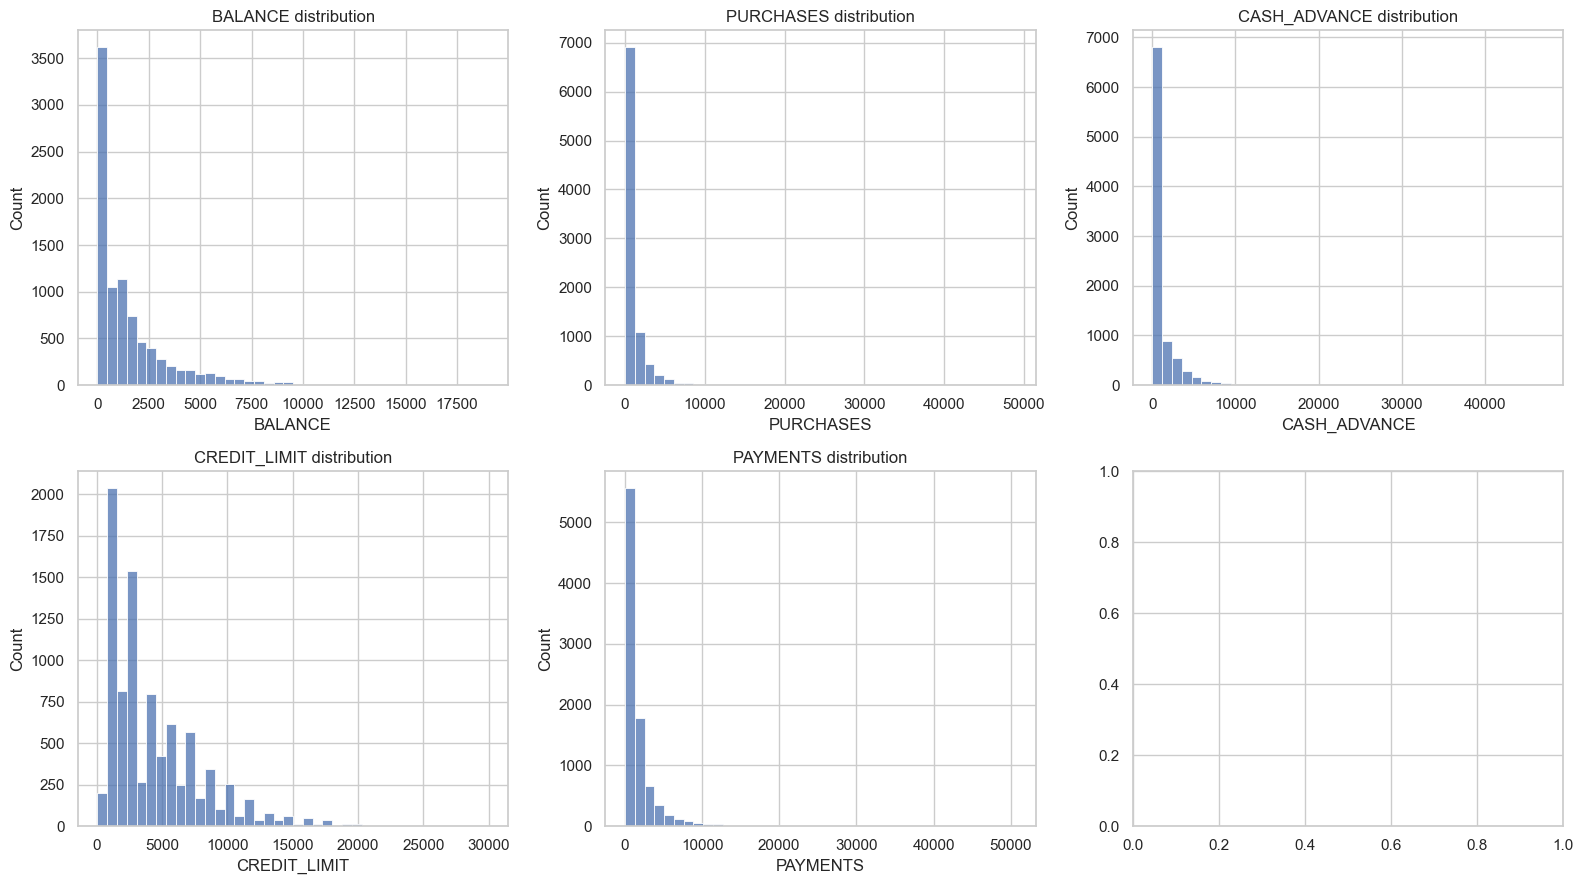

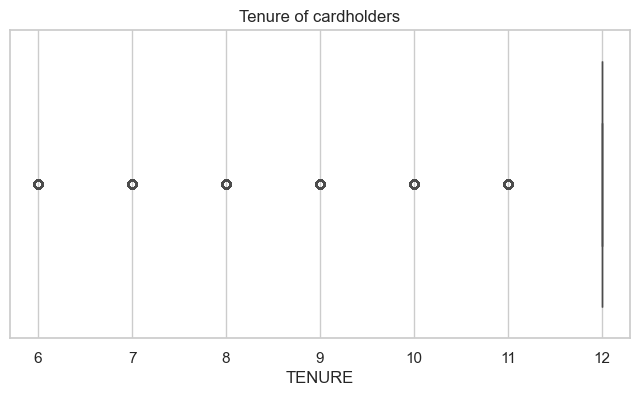

In [9]:
main_columns = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for column, ax in zip(main_columns, axes.flat):
    sns.histplot(df[column], bins=40, ax=ax)
    ax.set_title(f"{column} distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["TENURE"])
plt.title("Tenure of cardholders")
plt.show()

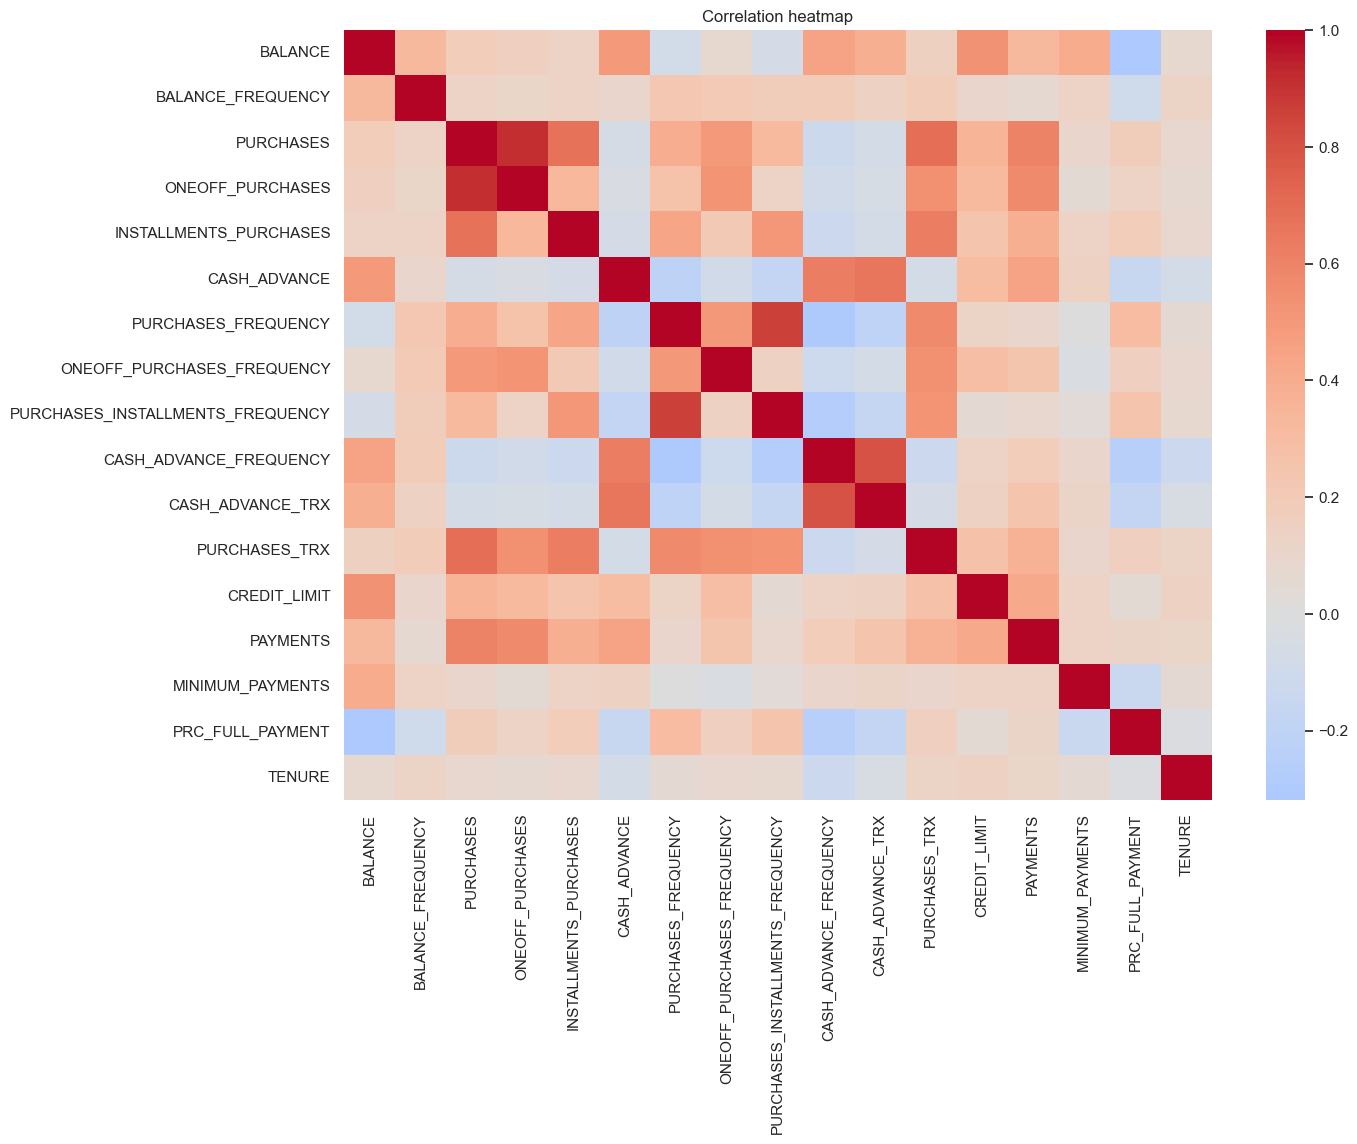

Strongest feature correlations:


PURCHASES               ONEOFF_PURCHASES                    0.916845
PURCHASES_FREQUENCY     PURCHASES_INSTALLMENTS_FREQUENCY    0.862934
CASH_ADVANCE_FREQUENCY  CASH_ADVANCE_TRX                    0.799561
PURCHASES               PURCHASES_TRX                       0.689561
                        INSTALLMENTS_PURCHASES              0.679896
CASH_ADVANCE            CASH_ADVANCE_TRX                    0.656498
                        CASH_ADVANCE_FREQUENCY              0.628522
INSTALLMENTS_PURCHASES  PURCHASES_TRX                       0.628108
PURCHASES               PAYMENTS                            0.603264
PURCHASES_FREQUENCY     PURCHASES_TRX                       0.568430
dtype: float64

In [10]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

correlation = df.corr(numeric_only=True).abs()
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
high_corr = upper.stack().sort_values(ascending=False)
print("Strongest feature correlations:")
display(high_corr.head(10))

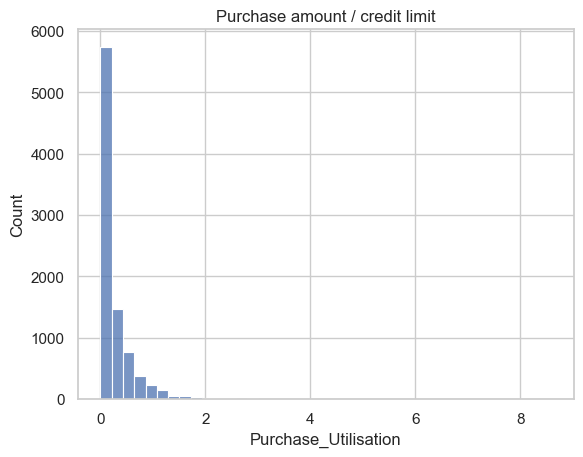

Top 10 customers by cash advance:


,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT
2159,10905.053810,431.93,47137.21176,19600.0
1059,8823.284205,3719.00,29282.10915,15500.0
71,2990.422186,4523.27,27296.48576,7000.0
7254,4530.205197,1750.66,26268.69989,8500.0
7645,7081.171387,0.00,26194.04954,9000.0
2454,10915.550750,0.00,23130.82106,15000.0
883,14581.459140,0.00,22665.77850,18500.0
6371,4529.895962,0.00,21943.84942,13000.0
3806,14100.251100,4995.80,20712.67008,16500.0
6455,9110.968989,1490.75,20277.33112,11000.0


Customers with no purchases: 22.84%
26.21% of customers account for about 80% of purchases.


In [11]:
# Purchase amount relative to credit limit (avoid division by zero).
df["Purchase_Utilisation"] = np.where(
    df["CREDIT_LIMIT"] > 0,
    df["PURCHASES"] / df["CREDIT_LIMIT"],
    0
)

sns.histplot(df["Purchase_Utilisation"], bins=40)
plt.title("Purchase amount / credit limit")
plt.show()

top_cash = df.nlargest(10, "CASH_ADVANCE")[["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT"]]
print("Top 10 customers by cash advance:")
display(top_cash)

zero_purchase_pct = (df["PURCHASES"].eq(0).mean()) * 100
print(f"Customers with no purchases: {zero_purchase_pct:.2f}%")

# Sort customers by purchase volume and find the share needed to reach 80% of purchases.
purchase_sorted = df["PURCHASES"].sort_values(ascending=False)
total_purchases = purchase_sorted.sum()
if total_purchases > 0:
    cumulative_share = purchase_sorted.cumsum() / total_purchases
    customers_for_80 = int((cumulative_share < 0.80).sum() + 1)
    percent_customers = customers_for_80 / len(df) * 100
    print(f"{percent_customers:.2f}% of customers account for about 80% of purchases.")
else:
    print("Total purchases are zero; Pareto calculation is not meaningful.")

## 5. Feature engineering and preprocessing

We add monthly averages and ratios that describe customer behaviour. Then we cap unusually high values using the upper IQR limit and apply `log1p` to monetary columns to reduce right-skew.

We keep the original-value dataframe separately so cluster profiles are easy to interpret.

In [12]:
features = df.copy()

# Avoid division by zero when calculating monthly averages.
tenure_safe = features["TENURE"].replace(0, np.nan)
features["Monthly_Avg_Purchase"] = (features["PURCHASES"] / tenure_safe).fillna(0)
features["Monthly_Avg_Cash_Advance"] = (features["CASH_ADVANCE"] / tenure_safe).fillna(0)

features["Limit_Usage"] = np.where(
    features["CREDIT_LIMIT"] > 0,
    features["BALANCE"] / features["CREDIT_LIMIT"],
    0
)
features["Payment_to_Minpayment_Ratio"] = (
    features["PAYMENTS"] / (features["MINIMUM_PAYMENTS"] + 1)
)

engineered_columns = [
    "Monthly_Avg_Purchase", "Monthly_Avg_Cash_Advance",
    "Limit_Usage", "Payment_to_Minpayment_Ratio"
]
display(features[engineered_columns].head())
display(features[engineered_columns].describe())

,Monthly_Avg_Purchase,Monthly_Avg_Cash_Advance,Limit_Usage,Payment_to_Minpayment_Ratio
0,7.950000,0.000000,0.040901,1.436214
1,0.000000,536.912124,0.457495,3.822677
2,64.430833,0.000000,0.332687,0.990103
3,124.916667,17.149001,0.222223,0.000000
4,1.333333,0.000000,0.681429,2.759800


,Monthly_Avg_Purchase,Monthly_Avg_Cash_Advance,Limit_Usage,Payment_to_Minpayment_Ratio
count,8950.000000,8950.000000,8950.000000,8950.000000
mean,86.175173,88.977984,0.388884,6.390555
std,180.508787,193.136115,0.389722,31.995344
min,0.000000,0.000000,0.000000,0.000000
25%,3.399375,0.000000,0.041494,0.910572
50%,31.936667,0.000000,0.302720,2.016643
75%,97.228333,99.085196,0.717571,6.013980
max,4086.630833,3928.100980,15.909951,1863.850036


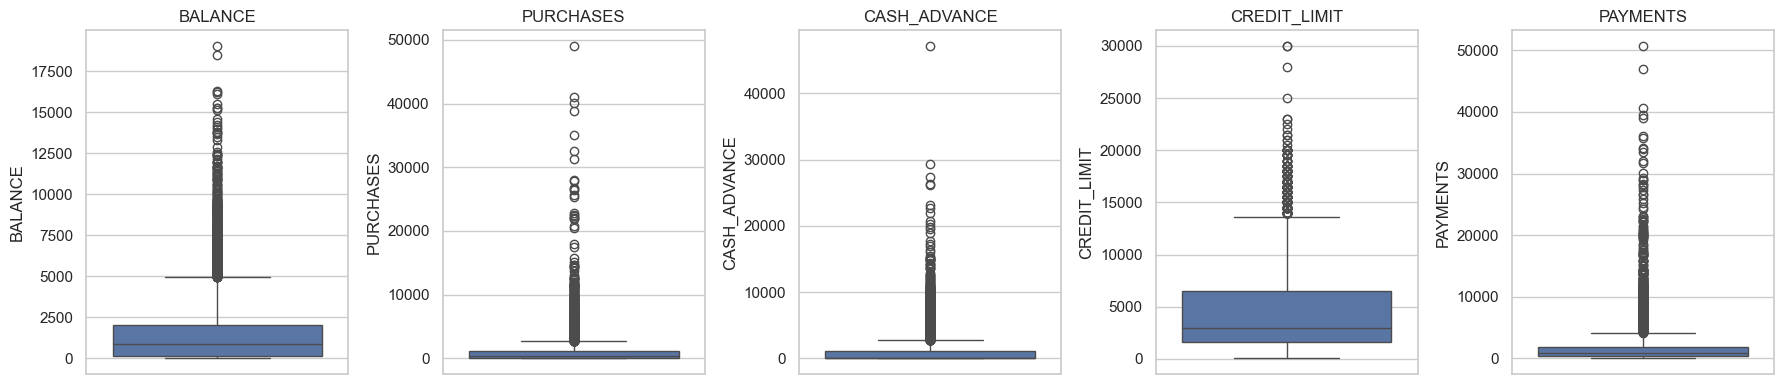

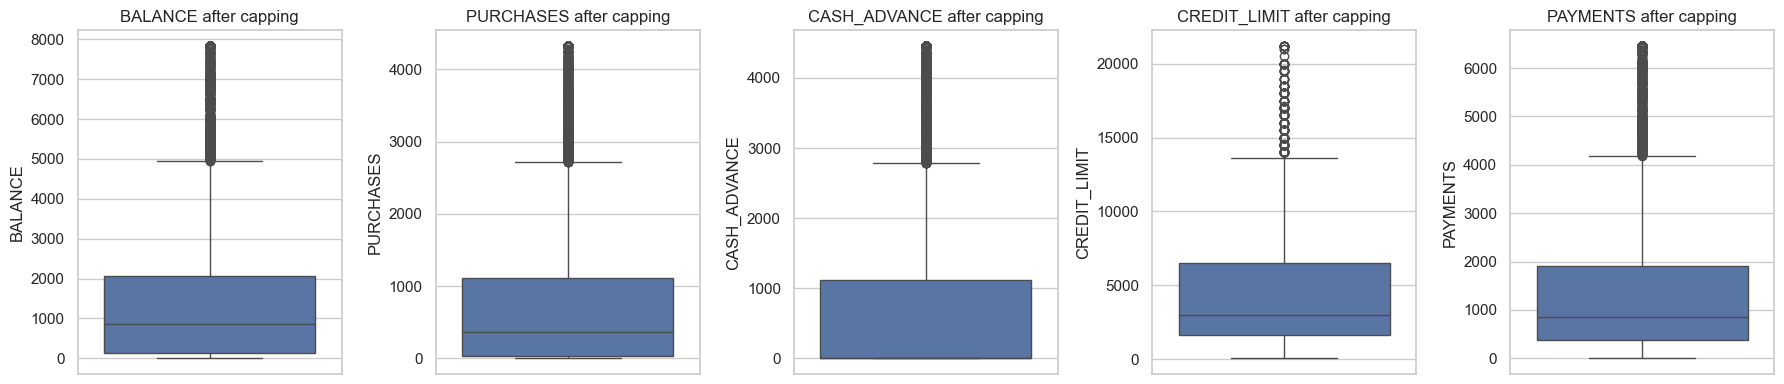

In [13]:
outlier_columns = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]

fig, axes = plt.subplots(1, len(outlier_columns), figsize=(18, 4))
for column, ax in zip(outlier_columns, axes):
    sns.boxplot(y=features[column], ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

# Cap only values above Q3 + 3 * IQR, as specified in the project brief.
for column in outlier_columns:
    q1 = features[column].quantile(0.25)
    q3 = features[column].quantile(0.75)
    iqr = q3 - q1
    upper_limit = q3 + 3 * iqr
    features[column] = features[column].clip(upper=upper_limit)

fig, axes = plt.subplots(1, len(outlier_columns), figsize=(18, 4))
for column, ax in zip(outlier_columns, axes):
    sns.boxplot(y=features[column], ax=ax)
    ax.set_title(f"{column} after capping")
plt.tight_layout()
plt.show()

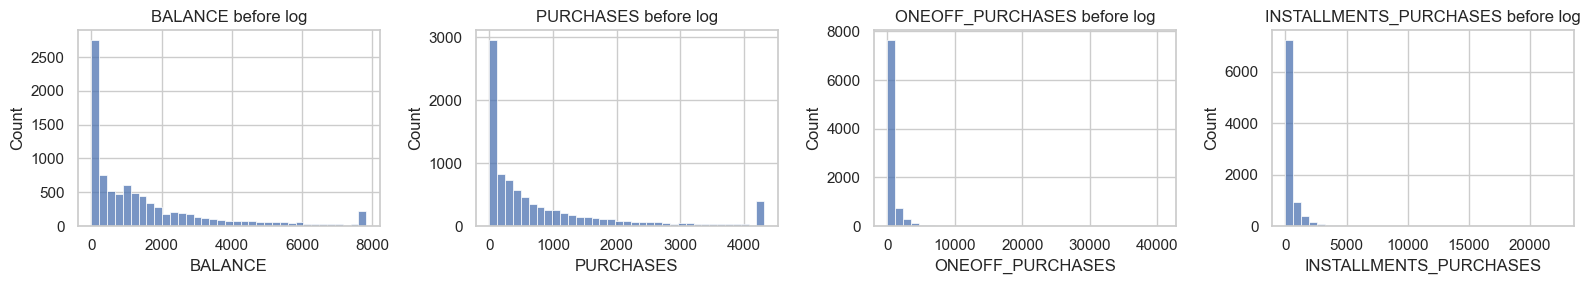

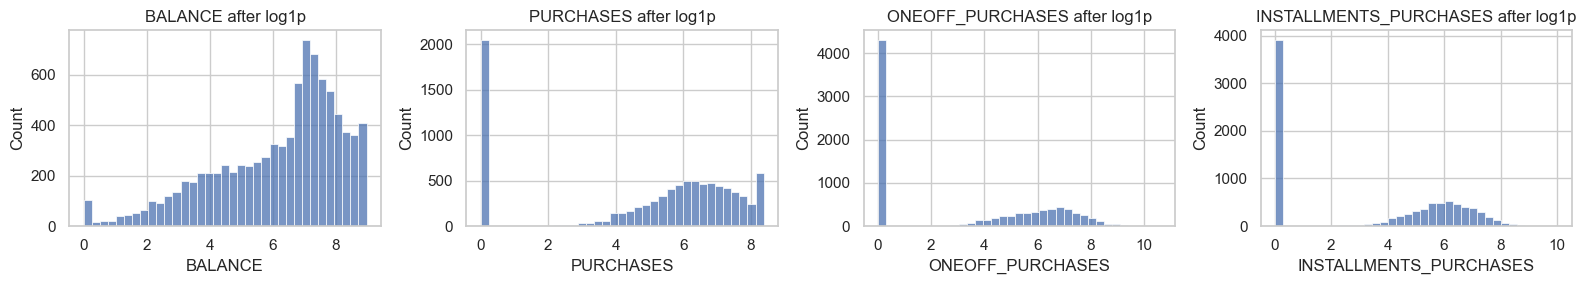

In [14]:
# Log transform monetary fields. log1p also works when values are zero.
monetary_columns = [
    "BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS",
    "PRC_FULL_PAYMENT", "Monthly_Avg_Purchase", "Monthly_Avg_Cash_Advance"
]
monetary_columns = [c for c in monetary_columns if c in features.columns]

fig, axes = plt.subplots(1, min(4, len(monetary_columns)), figsize=(16, 3))
for column, ax in zip(monetary_columns[:4], np.array(axes).reshape(-1)):
    sns.histplot(features[column], bins=35, ax=ax)
    ax.set_title(f"{column} before log")
plt.tight_layout()
plt.show()

model_features = features.copy()
for column in monetary_columns:
    # Monetary values in this dataset are non-negative.
    model_features[column] = np.log1p(model_features[column].clip(lower=0))

fig, axes = plt.subplots(1, min(4, len(monetary_columns)), figsize=(16, 3))
for column, ax in zip(monetary_columns[:4], np.array(axes).reshape(-1)):
    sns.histplot(model_features[column], bins=35, ax=ax)
    ax.set_title(f"{column} after log1p")
plt.tight_layout()
plt.show()

In [15]:
# StandardScaler is fitted on the features used for clustering.
scaler = StandardScaler()
cc_scaled = scaler.fit_transform(model_features)

scaled_df = pd.DataFrame(cc_scaled, columns=model_features.columns, index=model_features.index)
print("Scaled feature means (close to 0):")
display(scaled_df.mean().round(3).to_frame("mean").T)
print("Scaled feature standard deviations (close to 1):")
display(scaled_df.std().round(3).to_frame("std").T)

# Save the exact feature order for later use.
feature_columns = list(model_features.columns)

Scaled feature means (close to 0):


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Purchase_Utilisation,Monthly_Avg_Purchase,Monthly_Avg_Cash_Advance,Limit_Usage,Payment_to_Minpayment_Ratio
mean,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0


Scaled feature standard deviations (close to 1):


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Purchase_Utilisation,Monthly_Avg_Purchase,Monthly_Avg_Cash_Advance,Limit_Usage,Payment_to_Minpayment_Ratio
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 6. K-Means clustering

We compare k values from 2 to 10 using inertia and silhouette score. The elbow chart helps identify diminishing returns, while silhouette measures how well-separated the clusters are.

  File "c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\giris\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


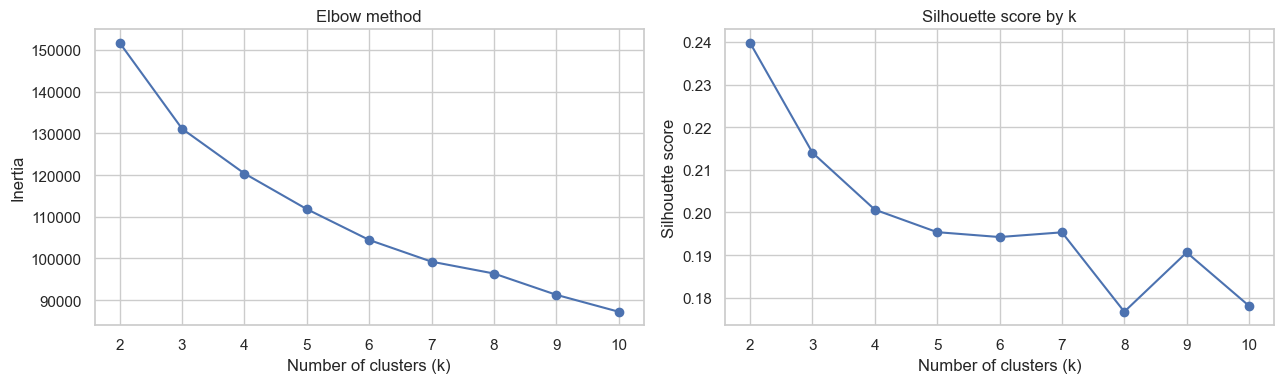

,k,inertia,silhouette
0,2,151707.470955,0.239791
1,3,131103.641590,0.214023
2,4,120370.035089,0.200661
3,5,111826.660757,0.195376
4,6,104430.797799,0.194232
5,7,99225.113202,0.195336
6,8,96384.040387,0.176709
7,9,91276.865792,0.190617
8,10,87218.552977,0.178079


Selected k: 2


In [16]:
k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(cc_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(cc_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

score_table = pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette": silhouette_scores})
display(score_table)

# Select the highest silhouette k as a transparent starting point.
# Review the elbow chart too; if a nearby k is more sensible, change this value.
k_optimal = int(score_table.loc[score_table["silhouette"].idxmax(), "k"])
print("Selected k:", k_optimal)

In [17]:
kmeans_model = KMeans(
    n_clusters=k_optimal, init="k-means++", n_init=20,
    max_iter=500, random_state=RANDOM_STATE
)
kmeans_labels = kmeans_model.fit_predict(cc_scaled)

results = df.copy()
results["KMeans_Cluster"] = kmeans_labels
display(results.head())

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Purchase_Utilisation,KMeans_Cluster
0,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,0.095400,0
1,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,0.000000,1
2,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,0.103089,0
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.343947,0.000000,12,0.199867,0
4,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,0.013333,1


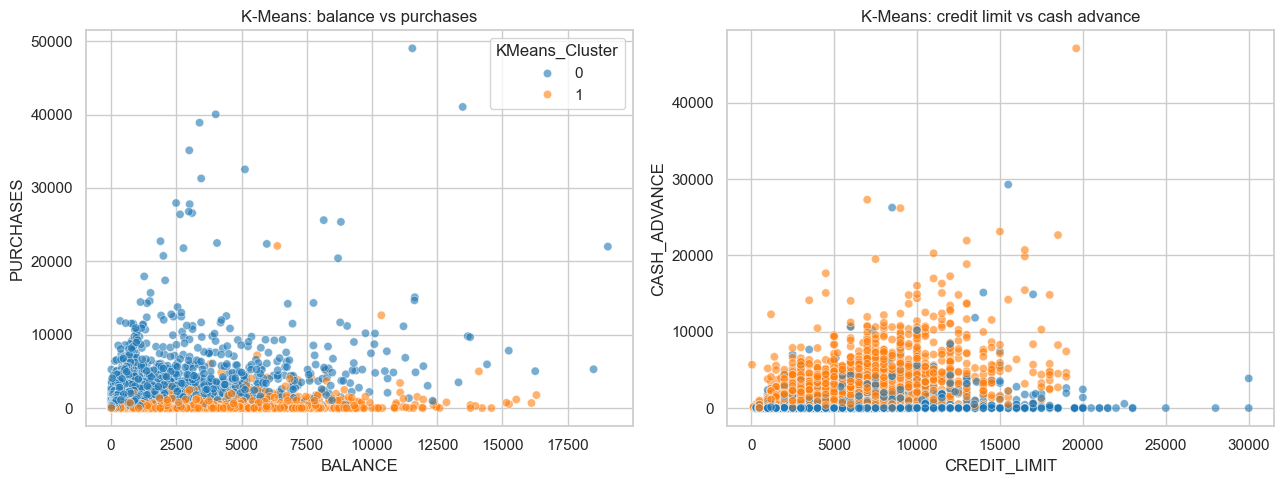

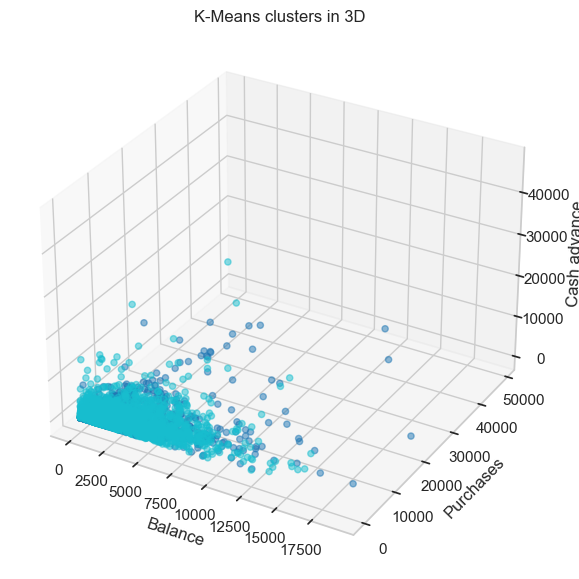

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=results, x="BALANCE", y="PURCHASES", hue="KMeans_Cluster",
                palette="tab10", alpha=0.6, ax=axes[0], legend="full")
axes[0].set_title("K-Means: balance vs purchases")
sns.scatterplot(data=results, x="CREDIT_LIMIT", y="CASH_ADVANCE", hue="KMeans_Cluster",
                palette="tab10", alpha=0.6, ax=axes[1], legend=False)
axes[1].set_title("K-Means: credit limit vs cash advance")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(results["BALANCE"], results["PURCHASES"], results["CASH_ADVANCE"],
                     c=kmeans_labels, cmap="tab10", alpha=0.5)
ax.set_xlabel("Balance")
ax.set_ylabel("Purchases")
ax.set_zlabel("Cash advance")
ax.set_title("K-Means clusters in 3D")
plt.show()

In [19]:
profile_columns = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "TENURE"]
kmeans_profile = results.groupby("KMeans_Cluster")[profile_columns].mean().sort_values("CREDIT_LIMIT", ascending=False)
display(kmeans_profile.round(2))

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE
KMeans_Cluster,,,,,,
0,1003.94,1493.6,212.8,4545.16,1656.12,11.63
1,2469.99,211.0,2216.4,4412.09,1857.57,11.34


### K-Means customer personas

Use the profile table above to name the groups based on their actual average values. These are example persona labels, not fixed meanings:

- **Premium Revolvers:** comparatively high balances and credit limits.
- **Frequent Transactors:** higher purchase and payment activity.
- **Cash-Advance Reliant:** relatively high cash advances.
- **Low-Activity / Dormant:** low purchase and payment activity.
- **New-to-Card:** shorter tenure, where the profile supports this interpretation.

A cluster number has no built-in business meaning. Check the profile before assigning a persona.

## 7. Agglomerative Hierarchical Clustering

Ward linkage builds a hierarchy by merging groups while trying to keep within-cluster variance low. The dendrogram gives a visual view of the merge distances.

The full dataset can make hierarchical linkage memory-intensive. If your computer runs out of memory, use a random sample for the dendrogram only; keep the final model fit on a suitable dataset size.

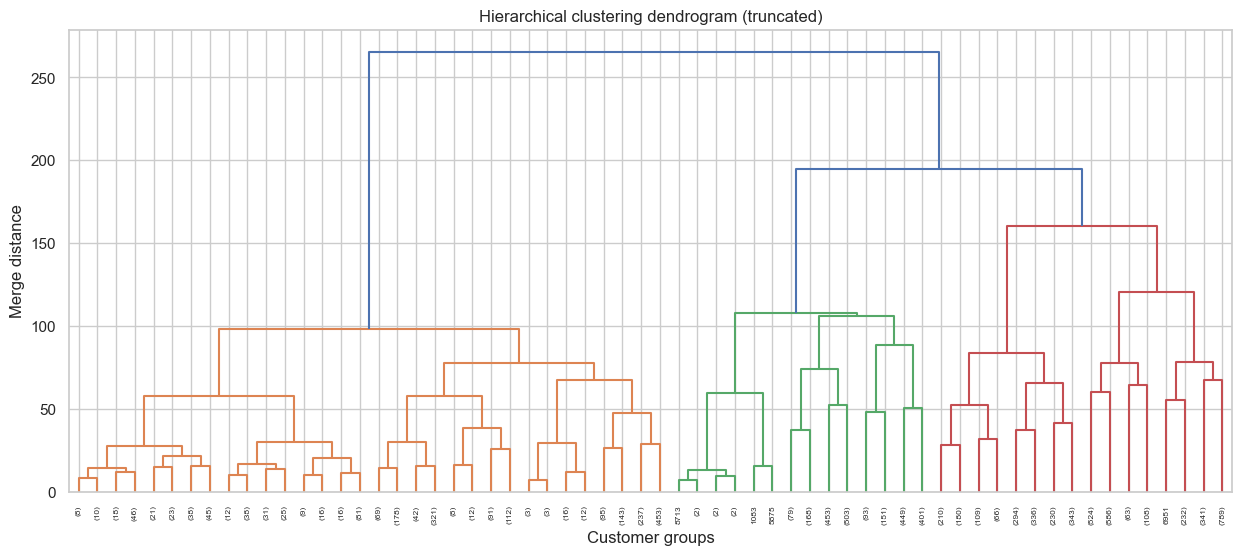

In [20]:
linkage_matrix = linkage(cc_scaled, method="ward")

plt.figure(figsize=(15, 6))
dendrogram(linkage_matrix, truncate_mode="level", p=5)
plt.title("Hierarchical clustering dendrogram (truncated)")
plt.xlabel("Customer groups")
plt.ylabel("Merge distance")
plt.show()

In [21]:
# Start with the same number of clusters as K-Means for an easier comparison.
n_chosen = k_optimal
linkage_results = {}

for method in ["ward", "complete", "average"]:
    agg_model = AgglomerativeClustering(n_clusters=n_chosen, linkage=method)
    labels = agg_model.fit_predict(cc_scaled)
    linkage_results[method] = {
        "model": agg_model,
        "labels": labels,
        "silhouette": silhouette_score(cc_scaled, labels)
    }

linkage_comparison = pd.DataFrame([
    {"linkage": method, "silhouette": values["silhouette"]}
    for method, values in linkage_results.items()
]).sort_values("silhouette", ascending=False)

display(linkage_comparison)
best_linkage = linkage_comparison.iloc[0]["linkage"]
agg_model = linkage_results[best_linkage]["model"]
agg_labels = linkage_results[best_linkage]["labels"]
results["Agg_Cluster"] = agg_labels
print("Selected linkage:", best_linkage)

,linkage,silhouette
1,complete,0.880654
2,average,0.880654
0,ward,0.203588


Selected linkage: complete


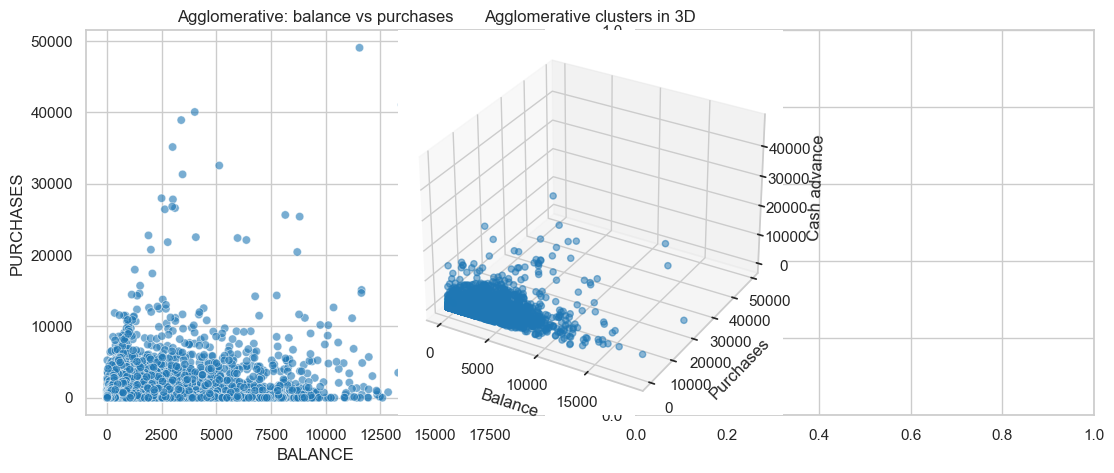

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE
Agg_Cluster,,,,,,
1,5.14,992.81,1388.60,6750.00,6529.90,12.00
0,1564.82,1003.21,978.78,4493.78,1732.07,11.52


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=results, x="BALANCE", y="PURCHASES", hue="Agg_Cluster",
                palette="tab10", alpha=0.6, ax=axes[0])
axes[0].set_title("Agglomerative: balance vs purchases")

ax = fig.add_subplot(111, projection="3d")
ax.scatter(results["BALANCE"], results["PURCHASES"], results["CASH_ADVANCE"],
           c=agg_labels, cmap="tab10", alpha=0.5)
ax.set_xlabel("Balance")
ax.set_ylabel("Purchases")
ax.set_zlabel("Cash advance")
ax.set_title("Agglomerative clusters in 3D")
plt.show()

agg_profile = results.groupby("Agg_Cluster")[profile_columns].mean().sort_values("CREDIT_LIMIT", ascending=False)
display(agg_profile.round(2))

In [23]:
# A simple comparison of the two sets of labels.
print("K-Means cluster counts:")
display(results["KMeans_Cluster"].value_counts().sort_index())
print("Agglomerative cluster counts:")
display(results["Agg_Cluster"].value_counts().sort_index())

K-Means cluster counts:


KMeans_Cluster
0    5528
1    3422
Name: count, dtype: int64

Agglomerative cluster counts:


Agg_Cluster
0    8948
1       2
Name: count, dtype: int64

## 8. DBSCAN clustering

DBSCAN groups dense regions and marks observations outside those regions as noise (`-1`). The k-nearest-neighbour distance curve helps choose a starting epsilon value.

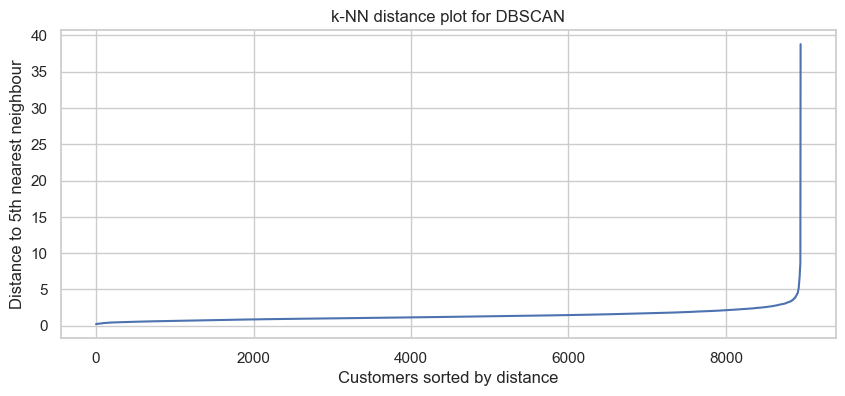

Starting epsilon (90th percentile heuristic): 2.18
Please inspect the k-NN plot and adjust optimal_eps if needed.


In [24]:
min_samples_start = 5
neighbors = NearestNeighbors(n_neighbors=min_samples_start).fit(cc_scaled)
distances, indices = neighbors.kneighbors(cc_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 4))
plt.plot(k_distances)
plt.title("k-NN distance plot for DBSCAN")
plt.xlabel("Customers sorted by distance")
plt.ylabel("Distance to 5th nearest neighbour")
plt.show()

# Choose an initial epsilon by inspecting the bend in the plot.
# Update this value if the curve suggests a different distance.
optimal_eps = float(np.percentile(k_distances, 90))
print("Starting epsilon (90th percentile heuristic):", round(optimal_eps, 3))
print("Please inspect the k-NN plot and adjust optimal_eps if needed.")

In [25]:
dbscan_model = DBSCAN(eps=optimal_eps, min_samples=5, metric="euclidean")
dbscan_labels = dbscan_model.fit_predict(cc_scaled)
results["DBSCAN_Cluster"] = dbscan_labels

cluster_ids = set(dbscan_labels) - {-1}
noise_count = int(np.sum(dbscan_labels == -1))
noise_pct = noise_count / len(dbscan_labels) * 100

print("Clusters excluding noise:", len(cluster_ids))
print("Noise points:", noise_count)
print(f"Noise percentage: {noise_pct:.2f}%")

Clusters excluding noise: 4
Noise points: 500
Noise percentage: 5.59%


In [26]:
eps_values = [0.3, 0.5, 0.7, 1.0, 1.5]
min_samples_values = [3, 5, 8, 10]
dbscan_grid = []

for eps in eps_values:
    for min_samples in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(cc_scaled)
        non_noise = labels != -1
        remaining_labels = labels[non_noise]
        number_clusters = len(set(remaining_labels))

        score = np.nan
        if number_clusters >= 2 and non_noise.sum() > number_clusters:
            score = silhouette_score(cc_scaled[non_noise], remaining_labels)

        dbscan_grid.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": number_clusters,
            "noise_percent": (labels == -1).mean() * 100,
            "silhouette": score
        })

dbscan_grid_df = pd.DataFrame(dbscan_grid)
display(dbscan_grid_df)

,eps,min_samples,clusters,noise_percent,silhouette
0,0.3,3,28,98.100559,0.367661
1,0.3,5,7,99.094972,0.268522
2,0.3,8,1,99.776536,NaN
3,0.3,10,1,99.810056,NaN
4,0.5,3,101,89.430168,0.066591
5,0.5,5,31,93.798883,0.152689
6,0.5,8,5,96.949721,0.331921
7,0.5,10,3,97.329609,0.401550
8,0.7,3,145,75.497207,-0.089682
9,0.7,5,41,82.379888,-0.055284


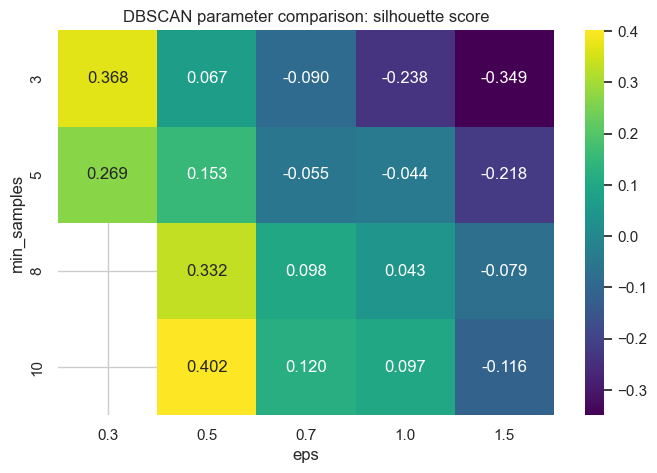

Selected DBSCAN parameters: 0.5 10


In [27]:
heatmap_data = dbscan_grid_df.pivot(index="min_samples", columns="eps", values="silhouette")
plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, cmap="viridis", fmt=".3f")
plt.title("DBSCAN parameter comparison: silhouette score")
plt.show()

valid_grid = dbscan_grid_df.dropna(subset=["silhouette"])
if len(valid_grid) > 0:
    best_row = valid_grid.sort_values("silhouette", ascending=False).iloc[0]
    best_eps = float(best_row["eps"])
    best_min_samples = int(best_row["min_samples"])
else:
    # Fallback: use the starting values when no tested combination forms 2+ clusters.
    best_eps, best_min_samples = optimal_eps, 5

print("Selected DBSCAN parameters:", best_eps, best_min_samples)
best_dbscan_model = DBSCAN(eps=best_eps, min_samples=best_min_samples)
best_dbscan_labels = best_dbscan_model.fit_predict(cc_scaled)
results["DBSCAN_Cluster"] = best_dbscan_labels

DBSCAN clusters excluding noise: 3
Noise points: 8711
Noise percentage: 97.33%


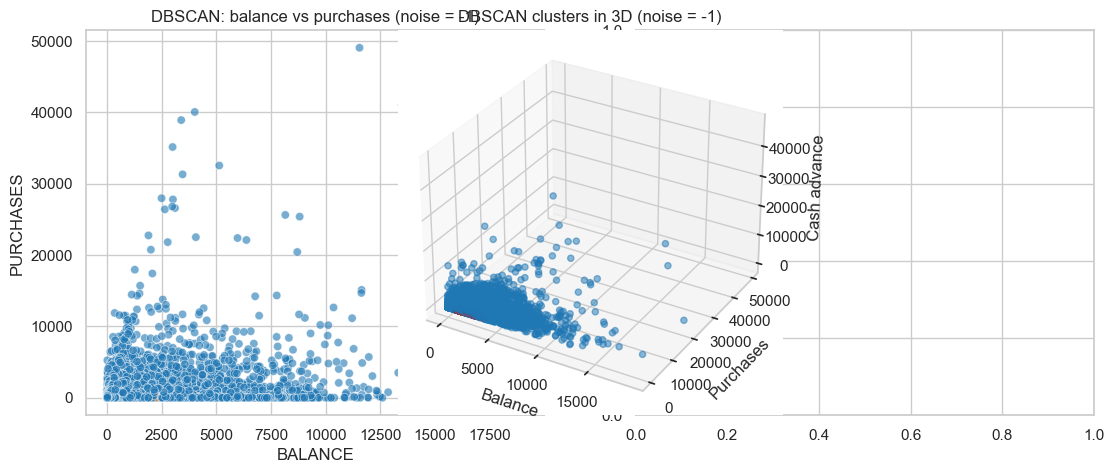

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE
DBSCAN_Cluster,,,,,,
0,1607.42,0.00,197.90,1787.74,455.52,12.0
1,32.61,444.81,0.00,2323.53,439.32,12.0
2,1455.52,0.00,377.64,1560.00,535.77,12.0


In [28]:
dbscan_clusters = set(best_dbscan_labels) - {-1}
best_noise_count = int(np.sum(best_dbscan_labels == -1))
best_noise_pct = best_noise_count / len(best_dbscan_labels) * 100

print("DBSCAN clusters excluding noise:", len(dbscan_clusters))
print("Noise points:", best_noise_count)
print(f"Noise percentage: {best_noise_pct:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_data = results.copy()
plot_data["DBSCAN_Display"] = plot_data["DBSCAN_Cluster"].astype(str)
sns.scatterplot(data=plot_data, x="BALANCE", y="PURCHASES", hue="DBSCAN_Display",
                alpha=0.6, ax=axes[0], palette="tab10")
axes[0].set_title("DBSCAN: balance vs purchases (noise = -1)")
axes[0].legend(title="Cluster")

ax = fig.add_subplot(111, projection="3d")
ax.scatter(results["BALANCE"], results["PURCHASES"], results["CASH_ADVANCE"],
           c=best_dbscan_labels, cmap="tab10", alpha=0.5)
ax.set_xlabel("Balance")
ax.set_ylabel("Purchases")
ax.set_zlabel("Cash advance")
ax.set_title("DBSCAN clusters in 3D (noise = -1)")
plt.show()

if len(dbscan_clusters) > 0:
    dbscan_profile = results[results["DBSCAN_Cluster"] != -1].groupby("DBSCAN_Cluster")[profile_columns].mean()
    display(dbscan_profile.round(2))
else:
    print("No non-noise clusters were found with the selected settings.")

## 9. Compare clustering algorithms

Silhouette is higher when clusters are better separated. Davies-Bouldin is lower when clusters are more compact and distinct. Calinski-Harabasz is generally higher when between-cluster separation is strong.

For DBSCAN, internal metrics are calculated on non-noise points only. If DBSCAN finds fewer than two clusters, its scores are recorded as unavailable.

In [29]:
def calculate_metrics(name, labels, parameters, noise_percent=0):
    labels = np.asarray(labels)
    non_noise = labels != -1
    valid_labels = labels[non_noise]
    valid_data = cc_scaled[non_noise]
    number_clusters = len(set(valid_labels))

    silhouette = np.nan
    davies = np.nan
    calinski = np.nan

    if number_clusters >= 2 and len(valid_labels) > number_clusters:
        silhouette = silhouette_score(valid_data, valid_labels)
        davies = davies_bouldin_score(valid_data, valid_labels)
        calinski = calinski_harabasz_score(valid_data, valid_labels)

    return {
        "Algorithm": name,
        "Parameters": parameters,
        "Clusters": number_clusters,
        "Silhouette": silhouette,
        "Davies_Bouldin": davies,
        "Calinski_Harabasz": calinski,
        "Noise_%": noise_percent
    }

comparison = pd.DataFrame([
    calculate_metrics("K-Means", kmeans_labels, f"k={k_optimal}"),
    calculate_metrics("Agglomerative", agg_labels, f"n_clusters={n_chosen}, linkage={best_linkage}"),
    calculate_metrics("DBSCAN", best_dbscan_labels, f"eps={best_eps}, min_samples={best_min_samples}", best_noise_pct)
])
display(comparison)

,Algorithm,Parameters,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Noise_%
0,K-Means,k=2,2,0.239827,1.603044,2665.554126,0.000000
1,Agglomerative,"n_clusters=2, linkage=complete",2,0.880654,0.237356,247.211360,0.000000
2,DBSCAN,"eps=0.5, min_samples=10",3,0.401550,0.540544,582.684656,97.329609


## 10. K-Means stability check

We train K-Means five times with different random seeds and compare the silhouette scores.

In [30]:
stability_rows = []
for seed in [0, 7, 21, 42, 99]:
    model = KMeans(n_clusters=k_optimal, n_init=20, random_state=seed)
    labels = model.fit_predict(cc_scaled)
    stability_rows.append({
        "random_state": seed,
        "silhouette": silhouette_score(cc_scaled, labels)
    })

stability_df = pd.DataFrame(stability_rows)
display(stability_df)
print(f"Mean silhouette: {stability_df['silhouette'].mean():.4f}")
print(f"Standard deviation: {stability_df['silhouette'].std():.4f}")

,random_state,silhouette
0,0,0.239732
1,7,0.239812
2,21,0.239865
3,42,0.239827
4,99,0.239843


Mean silhouette: 0.2398
Standard deviation: 0.0001


## 11. Business interpretation and recommendation

Use the profile tables and metric comparison to complete this section with the actual results from your run.

### Suggested way to write the recommendation

**To: Head of Cards & Payments**

The analysis groups cardholders using their observed balance, purchase, cash-advance, payment and tenure behaviour. I recommend the algorithm that offers the best balance of internal evaluation scores, usable segment sizes and clear business interpretation. A slightly lower metric score may still be acceptable if the resulting segments are easier for Relationship Managers to action.

For each final segment, describe its distinguishing behaviour and suggest one suitable action. Examples include a balance-transfer or EMI offer for customers with high revolving balances, rewards for active purchasers, a cash-advance education or affordability review for cash-advance-heavy customers, and a reactivation campaign for low-activity customers.

In a future iteration, the bank could add consented customer tenure and product information, repayment history, delinquency indicators, channel engagement, rewards redemption, and customer preferences. Any use of sensitive or regulated information should follow the bank's governance and applicable privacy requirements.

## 12. Save the scaler and final model

The final model saved here is K-Means because it supports assigning a new customer to the nearest learned cluster. Agglomerative clustering and standard DBSCAN do not provide a straightforward `predict` method for unseen customers.

The saved preprocessing feature list is also stored so new rows are transformed in the same column order.

In [31]:
# Save artifacts into the project models folder.
os.makedirs("../models", exist_ok=True)
joblib.dump(scaler, "../models/cc_scaler.pkl")
joblib.dump(kmeans_model, "../models/cc_segmentation_model.pkl")
joblib.dump(feature_columns, "../models/feature_columns.pkl")
print("Saved scaler, K-Means model and feature list in models/")

Saved scaler, K-Means model and feature list in models/


## 13. Predict a segment for a new cardholder

The example below uses hypothetical values only to demonstrate the function. Replace them with valid new-customer values when testing your own use case.

In [32]:
def prepare_new_customer(raw_values):
    new_customer = pd.DataFrame([raw_values])

    # Ensure all raw dataset columns are present and in the expected order.
    for column in df.columns:
        if column not in new_customer.columns:
            new_customer[column] = 0
    new_customer = new_customer[df.columns]

    # Recreate the engineered features.
    tenure = new_customer["TENURE"].replace(0, np.nan)
    new_customer["Monthly_Avg_Purchase"] = (
        new_customer["PURCHASES"] / tenure
    ).fillna(0)
    new_customer["Monthly_Avg_Cash_Advance"] = (
        new_customer["CASH_ADVANCE"] / tenure
    ).fillna(0)
    new_customer["Limit_Usage"] = np.where(
        new_customer["CREDIT_LIMIT"] > 0,
        new_customer["BALANCE"] / new_customer["CREDIT_LIMIT"],
        0
    )
    new_customer["Purchase_Utilisation"] = np.where(
        new_customer["CREDIT_LIMIT"] > 0,
        new_customer["PURCHASES"] / new_customer["CREDIT_LIMIT"],
        0
    )
    new_customer["Payment_to_Minpayment_Ratio"] = (
        new_customer["PAYMENTS"] / (new_customer["MINIMUM_PAYMENTS"] + 1)
    )

    # Apply the same upper-IQR caps learned from the training data.
    for column in outlier_columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        upper_limit = q3 + 3 * (q3 - q1)
        if column in new_customer.columns:
            new_customer[column] = new_customer[column].clip(upper=upper_limit)

    # Apply the same log transformations and column order.
    for column in monetary_columns:
        new_customer[column] = np.log1p(new_customer[column].clip(lower=0))

    new_customer = new_customer[feature_columns]
    return new_customer

# Create simple persona names from the actual K-Means cluster profiles.
# These rules are only a starting point; review and edit names after checking the profile table.
persona_profile = results.groupby("KMeans_Cluster")[profile_columns].mean()
persona_names = {}

for cluster_id, row in persona_profile.iterrows():
    if row["CASH_ADVANCE"] > row["PURCHASES"]:
        persona_names[int(cluster_id)] = "Cash-Advance Reliant"
    elif row["PURCHASES"] > persona_profile["PURCHASES"].median():
        persona_names[int(cluster_id)] = "Active Purchasers"
    elif row["BALANCE"] > persona_profile["BALANCE"].median():
        persona_names[int(cluster_id)] = "Balance Carriers"
    else:
        persona_names[int(cluster_id)] = "Low-Activity Customers"

def predict_segment(raw_values):
    prepared = prepare_new_customer(raw_values)
    scaled = scaler.transform(prepared)
    label = int(kmeans_model.predict(scaled)[0])
    persona = persona_names.get(label, "Review Cluster Profile")
    return label, persona

# Five made-up examples for testing the function.
sample_customers = [
    {"BALANCE": 4500, "PURCHASES": 2200, "CASH_ADVANCE": 0, "CREDIT_LIMIT": 10000, "PAYMENTS": 2500, "MINIMUM_PAYMENTS": 180, "TENURE": 12},
    {"BALANCE": 12000, "PURCHASES": 300, "CASH_ADVANCE": 4500, "CREDIT_LIMIT": 15000, "PAYMENTS": 500, "MINIMUM_PAYMENTS": 350, "TENURE": 10},
    {"BALANCE": 200, "PURCHASES": 0, "CASH_ADVANCE": 0, "CREDIT_LIMIT": 5000, "PAYMENTS": 0, "MINIMUM_PAYMENTS": 50, "TENURE": 6},
    {"BALANCE": 7000, "PURCHASES": 6500, "CASH_ADVANCE": 100, "CREDIT_LIMIT": 20000, "PAYMENTS": 7000, "MINIMUM_PAYMENTS": 250, "TENURE": 24},
    {"BALANCE": 2500, "PURCHASES": 900, "CASH_ADVANCE": 1800, "CREDIT_LIMIT": 8000, "PAYMENTS": 1200, "MINIMUM_PAYMENTS": 120, "TENURE": 18}
]

for number, customer in enumerate(sample_customers, start=1):
    print(f"Customer {number}: {customer}")
    predicted_cluster, predicted_persona = predict_segment(customer)
    print("Predicted cluster:", predicted_cluster)
    print("Suggested persona:", predicted_persona)
    print("-" * 60)

Customer 1: {'BALANCE': 4500, 'PURCHASES': 2200, 'CASH_ADVANCE': 0, 'CREDIT_LIMIT': 10000, 'PAYMENTS': 2500, 'MINIMUM_PAYMENTS': 180, 'TENURE': 12}
Predicted cluster: 0
Suggested persona: Active Purchasers
------------------------------------------------------------
Customer 2: {'BALANCE': 12000, 'PURCHASES': 300, 'CASH_ADVANCE': 4500, 'CREDIT_LIMIT': 15000, 'PAYMENTS': 500, 'MINIMUM_PAYMENTS': 350, 'TENURE': 10}
Predicted cluster: 1
Suggested persona: Cash-Advance Reliant
------------------------------------------------------------
Customer 3: {'BALANCE': 200, 'PURCHASES': 0, 'CASH_ADVANCE': 0, 'CREDIT_LIMIT': 5000, 'PAYMENTS': 0, 'MINIMUM_PAYMENTS': 50, 'TENURE': 6}
Predicted cluster: 1
Suggested persona: Cash-Advance Reliant
------------------------------------------------------------
Customer 4: {'BALANCE': 7000, 'PURCHASES': 6500, 'CASH_ADVANCE': 100, 'CREDIT_LIMIT': 20000, 'PAYMENTS': 7000, 'MINIMUM_PAYMENTS': 250, 'TENURE': 24}
Predicted cluster: 0
Suggested persona: Active Purc